# Tier 1 Exploration: Real Image and COCO Mask

This notebook loads and visualizes the real test image and its COCO polygon annotations. It does not implement attribution or the directional matrix.

In [1]:
from pathlib import Path

import csv
import matplotlib.pyplot as plt
from PIL import Image

from src.data_utils import load_image_and_mask, load_mask_from_coco

C:\Users\Gabriel\Documents\Faculdade\Sis Int Hib\.venv_fixlip\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Load the real image

The image is resized to 224 by 224 while the mask is loaded independently from the COCO JSON.

In [2]:
test_dir = Path("./tests")
image_path = test_dir / "test_img.JPEG"

with Image.open(image_path) as source_image:
    source_image_size = source_image.size

image_pil, _ = load_image_and_mask(
    image_path,
    mask_path=None,
    target_size=224,
)

mask_array, n_regions = load_mask_from_coco(
    test_dir / "test_mask.json",
    image_size=(224, 224),
    source_image_size=source_image_size,
)

print(f"Number of regions: {n_regions}")
print(f"Mask shape: {mask_array.shape}")

Number of regions: 5
Mask shape: (224, 224)


## Read the caption and visualize alignment

Caption: a baseball player throwing a ball


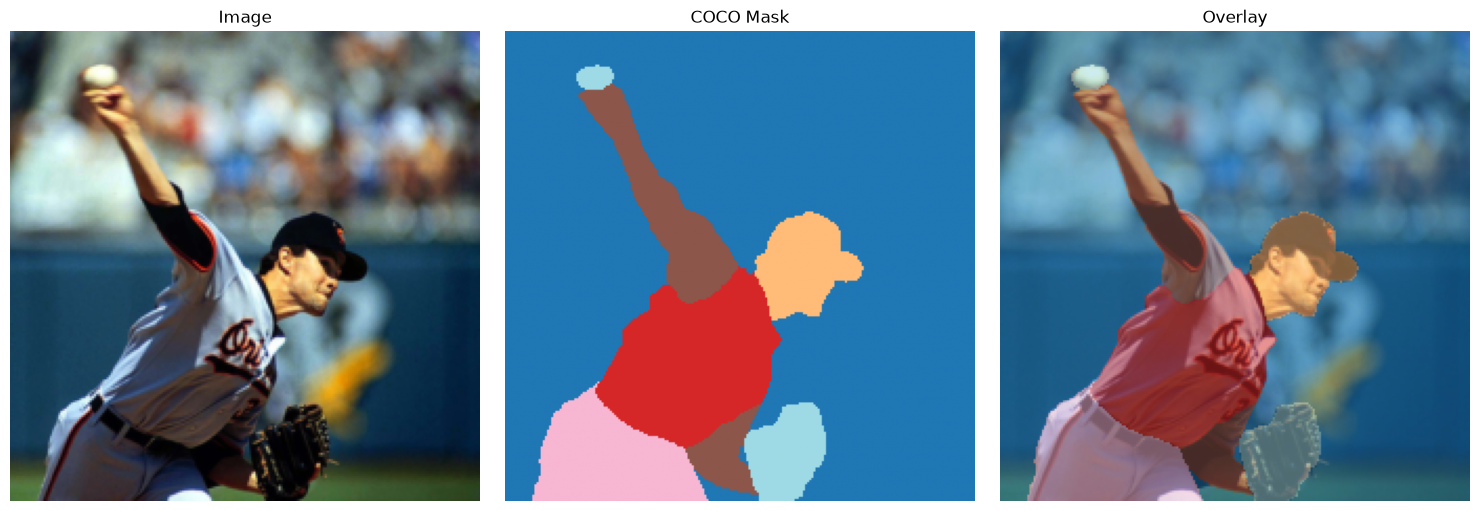

In [3]:
caption = None
with open(test_dir / "captions.csv", "r", newline="", encoding="utf-8") as csv_file:
    for row in csv.DictReader(csv_file):
        if row["image_file"] in {"test_img.jpeg", "test_img.jpg", "test_img.JPEG"}:
            caption = row["caption"]
            break

if caption is None:
    raise ValueError("Caption for test_img.jpeg was not found in captions.csv")

print(f"Caption: {caption}")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image_pil)
axes[0].set_title("Image")
axes[0].axis("off")

axes[1].imshow(mask_array, cmap="tab20")
axes[1].set_title("COCO Mask")
axes[1].axis("off")

axes[2].imshow(image_pil)
axes[2].imshow(mask_array, cmap="tab20", alpha=0.5)
axes[2].set_title("Overlay")
axes[2].axis("off")

fig.tight_layout()
plt.show()

## Test region perturbation

This cell validates that the perturbation function correctly removes only the pixels of the specified region, using the real image and real COCO mask.

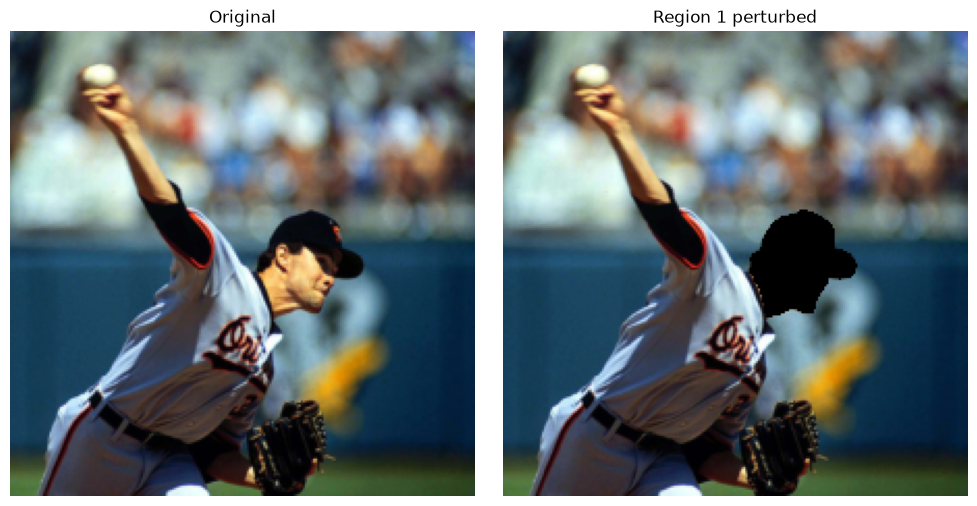

In [4]:
from src.perturbation import perturbar_regiao

n_regioes = int(mask_array.max())
region_id = 1

perturbed_image = perturbar_regiao(
    image_pil,
    mask_array,
    region_id=region_id,
    method="zero",
)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(image_pil)
axes[0].set_title("Original")
axes[0].axis("off")
axes[1].imshow(perturbed_image)
axes[1].set_title("Region 1 perturbed")
axes[1].axis("off")
fig.tight_layout()
plt.show()

## Base attribution

This cell computes a simple CLIP gradient saliency map for the real image and caption, then averages the attribution inside each real COCO region.


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 398/398 [00:00<00:00, 30608.06it/s]

Base attribution by region: [0.2139803  0.5116269  0.41672927 0.41390672 0.         0.5626121 ]


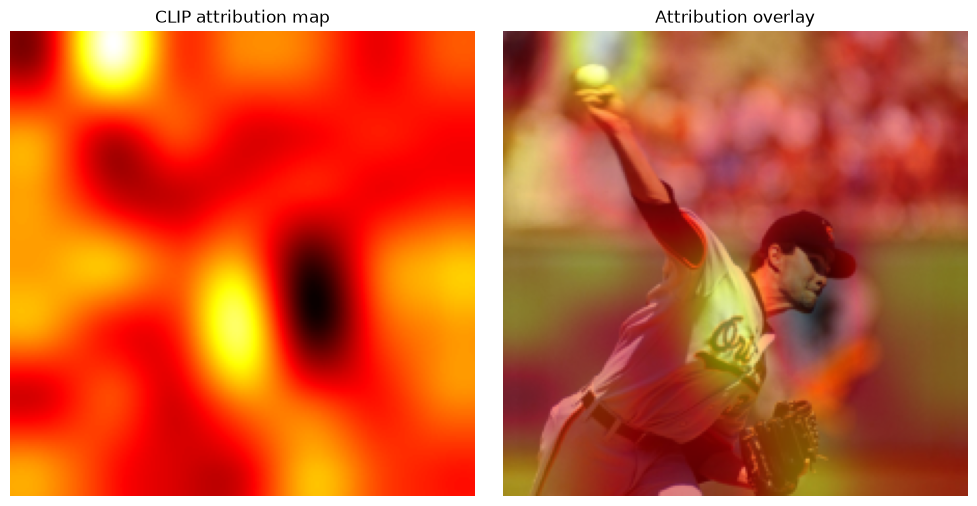

In [5]:
import torch

from src.attribution import calcular_phi_base, get_attribution_map

device = "cuda" if torch.cuda.is_available() else "cpu"
attribution_map = get_attribution_map(image_pil, caption, device=device)
phi_base = calcular_phi_base(
    image_pil,
    caption,
    mask_array,
    n_regioes,
    device=device,
)

print(f"Base attribution by region: {phi_base}")

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(attribution_map, cmap="hot")
axes[0].set_title("CLIP attribution map")
axes[0].axis("off")
axes[1].imshow(image_pil)
axes[1].imshow(attribution_map, cmap="hot", alpha=0.5)
axes[1].set_title("Attribution overlay")
axes[1].axis("off")
fig.tight_layout()
plt.show()

## Visualize regions used by the directional matrix

This visualization shows each real mask region as a colored contour and labels it with its region ID.

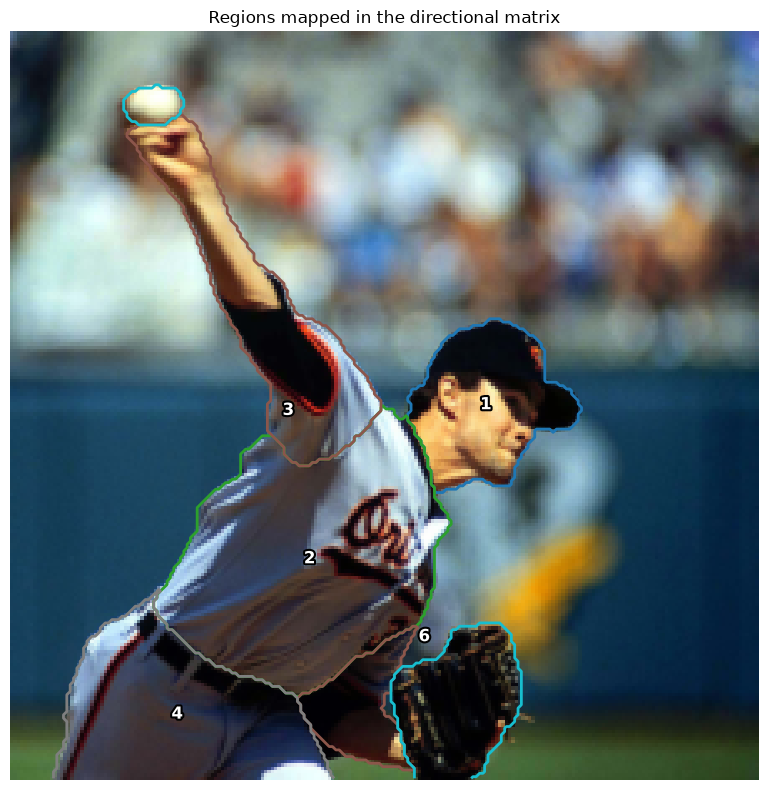

In [8]:
import matplotlib.patheffects as path_effects
import numpy as np

region_ids = [int(region_id) for region_id in np.unique(mask_array) if region_id != 0]
colors = plt.cm.tab10(np.linspace(0, 1, max(len(region_ids), 1)))
fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(image_pil)
for color, region_id in zip(colors, region_ids):
    region_pixels = mask_array == region_id
    ax.contour(
        region_pixels.astype(float),
        levels=[0.5],
        colors=[color],
        linewidths=2,
    )
    y_coordinates, x_coordinates = np.where(region_pixels)
    center_x = float(x_coordinates.mean())
    center_y = float(y_coordinates.mean())
    label = ax.text(
        center_x,
        center_y,
        str(region_id),
        color="white",
        ha="center",
        va="center",
        fontsize=12,
        fontweight="bold",
    )
    label.set_path_effects([
        path_effects.Stroke(linewidth=3, foreground="black"),
        path_effects.Normal(),
    ])

ax.set_title("Regions mapped in the directional matrix")
ax.axis("off")
fig.tight_layout()
fig.savefig("regions_visualization.png", dpi=150, bbox_inches="tight")
plt.show()

## Directional importance matrix

For each region j, this cell perturbs only region j, recomputes the regional base attribution, and records the change in each evaluated region i.

Directional importance matrix M:
[[-0.15116666  0.03745855 -0.03862952  0.01174679  0.         -0.00799426]
 [ 0.14345959  0.18537354 -0.0466966   0.06518248  0.         -0.04549754]
 [ 0.09639794  0.01203617  0.02173641  0.05916178  0.         -0.03717643]
 [ 0.11129579 -0.0404264  -0.17930451  0.19269754  0.         -0.0083386 ]
 [ 0.          0.          0.          0.          0.          0.        ]
 [ 0.07194471  0.02859223 -0.15918827  0.0644176   0.          0.19874722]]


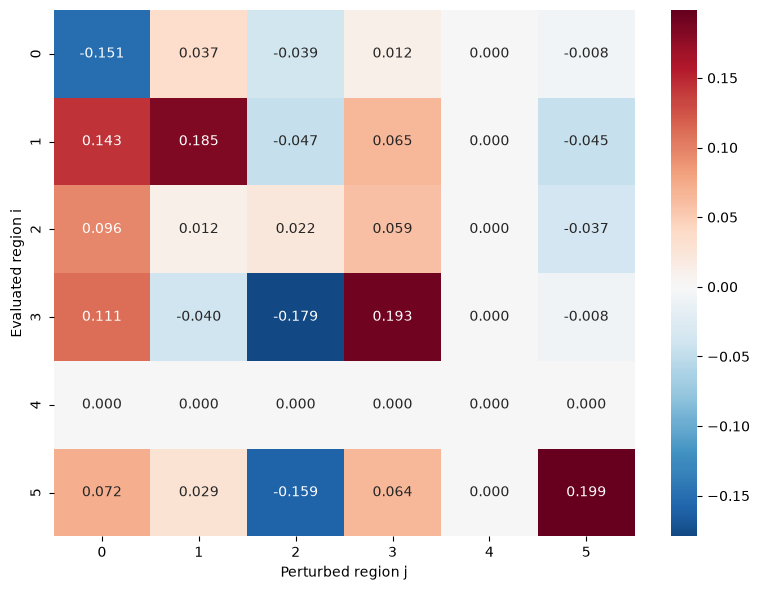

In [6]:
import seaborn as sns

from src.matrix import compute_directional_matrix

directional_matrix = compute_directional_matrix(
    image_pil,
    caption,
    mask_array,
    n_regioes,
    device=device,
)

print("Directional importance matrix M:")
print(directional_matrix)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    directional_matrix,
    annot=True,
    fmt=".3f",
    cmap="RdBu_r",
    center=0,
    ax=ax,
)
ax.set_xlabel("Perturbed region j")
ax.set_ylabel("Evaluated region i")
fig.tight_layout()
plt.show()

In [ ]:
from src.attribution import calcular_phi_base
from src.matrix import compute_directional_matrix
from src.mask_similarity import (
    compute_mask_similarity,
    predict_mask_similarity,
    quadratic_difference,
)

# Use the largest mask ID so non-contiguous IDs (including region 6) fit the matrix indices.
objective_n_regions = int(mask_array.max())
objective_phi_base = calcular_phi_base(
    image_pil,
    caption,
    mask_array,
    objective_n_regions,
    device=device,
)
objective_matrix = compute_directional_matrix(
    image_pil,
    caption,
    mask_array,
    objective_n_regions,
    device=device,
)
phi_0 = compute_mask_similarity(
    image_pil,
    caption,
    mask_array,
    visible_regions=[],
    device=device,
)

masks_to_test = ([1], [1, 3, 6], [1, 2, 3, 4, 5, 6])
for visible_regions in masks_to_test:
    v_real = compute_mask_similarity(
        image_pil,
        caption,
        mask_array,
        visible_regions,
        device=device,
    )
    v_pred = predict_mask_similarity(
        objective_phi_base,
        objective_matrix,
        visible_regions,
        phi_0=phi_0,
    )
    difference = quadratic_difference(v_real, v_pred)
    print(
        f"Visible regions {list(visible_regions)}: "
        f"v(M)={v_real:.6f}, v'(M)={v_pred:.6f}, "
        f"quadratic difference={difference:.6f}"
    )